# AP 155 Lab Exercise
---
## Exercise 11: Montecarlo Methods

_Instructions_:
- **Report Figures**:
 1. initial spin configuration, you choose  $T$
 2. spin configuration after 10,000 sweeps, for $T$ above and below $T_C$
 3. magnetization and energy, for $T$ above and below $T_C$
 4. magnetization and energy with external field, for $T$ above and below $T_C$
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: CRUZADO, JOHN CLARENCE
- _Student No._: 2024-03034
- _Section_: THU-WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness  | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figure


### (1) The Ising Model and (2) Metropolis Sweep Algorithm
<img src="Fig1.png" alt="Fig1" width=45%>

Figure 1. Initial random satate and final equilibriated sate of a $20\times20$ Ising model after $10,000$ Metropolis sweeps.

For a randomly initialized lattice, the expected initial magnetization is approximately zero due to random statistical cancellation of normally distributed spin values. For a ferromagnetic system where $J>0$, the energy is minimized and given by $E=-JN_{bonds}$ where, in this case, $N_{bonds}=2\times20\times20=800$.

### (3) Spontaneous Magnetization
<img src="Fig2-1.png" alt="Fig2-1" width=45%>

Figure 2-1. Initial random configurations (top row) and final states (bottom row) after $100,000$ spin flips across three independent simulation runs.

<img src="Fig2-2.png" alt="Fig2-2" width=45%>

Figure 2-2. Evolution of magnetization per spin $(m)$ and total energy $(H)$ over $100,000$ spin flips for three independent runs, showing rapid convergent to a stable energy plateau while magnetization stabilizes at varying paratial values due to the walls of the magnetic domain. This implies that the energy of the Ising model naturally converges to $E$ but the magnetization is dependent on the spin uniformity of the whole model.

The system develops spontaneous local order as domains of aligned spins form out of the random initial state, resulting in non-zero net magnetization values. Furthermore, separate and independent simulations can produce positive or negative magnetization because the Ising Hamiltonian is symmetric under a global spin inversion, where $S_i → -S_i$ which tells us that positive and negative states are degenerate. The formation of domain boundaries in early thermalization/simulation dictate whether a given run stabilizes with a positive, negative, or near-zero net magnetization.


### (4) Introducing an External Magnetic Field
<img src="Fig3.png" alt="Fig3" width=45%>

Figure 3. Initial random configuration and final fully aligned equilibriated state of the Ising model under an external magnetic field of magnitude $B=0.5%.

The external magnetic field explicitly breaks the up-down symmetry by contributing to the energy of the system, which now has a preferred direction. Unlike the zero-field case where both magnetization signs are equally probable, a non-zero external $B$ lifts the degeneracy and introduces a bias that drives the spins to align uniformly and favor a positve magnetization.

### (5) Critical Temperature
<img src="Fig4.png" alt="Fig4" width=45%>

Figure 4. Initial random configuration and final equilibriated stated of the Ising model at $T=3.0$.

<img src="Fig5.png" alt="Fig5" width=45%>

Figure 5. Initial random configuration and final equilibriated stated of the Ising model at $T=3.0$ in the presence of an external magnetic field $B=0.5$.

Temperature directly dictates the competition between thermal energy and exchange interactions, as given by the Boltzmann distribution. As temperature rises above the critical point, intensified thermal fluctuations disrupt long-range magnetic alignment, decreasing spontaneous magnetization and creating local magnetic domains.

---
## Section 2: Code

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math

# Exercise: The Two-Dimensional Ising Model

## Introduction

The Ising model describes the magnetic behavior of a material using interacting spins arranged on a lattice. Each spin can take one of two values, $S_{i,j}=\pm1$, representing spin-up and spin-down orientations.

In this exercise, you will simulate a two-dimensional Ising model using the **Metropolis Monte Carlo algorithm**. You will investigate how spin interactions, temperature, and external magnetic fields affect the system's energy and magnetization.

## 1. Setting Up the Ising Model

Consider a square lattice of size $N\times N$. Each spin interacts with its four nearest neighbors.

The energy of the system is given by the Ising Hamiltonian:

$$
H(\mathbf S)=-J\sum_{\langle ij\rangle}S_iS_j
$$

where $J$ is the interaction strength and the summation includes each unique neighboring pair exactly once.

Use **periodic boundary conditions**, where the lattice wraps around itself so that every spin has four neighbors.

**Tasks:**

1. Create a $20\times20$ lattice with randomly initialized spins of $+1$ or $-1$.
2. Plot the initial spin configuration.
3. Write a function to calculate the total energy using:

$$
H=-J\sum_{i,j}S_{i,j}(S_{i+1,j}+S_{i,j+1})
$$

**Guide questions:**
- What is the expected initial magnetization?
- What is the energy of a completely aligned lattice when $J>0$?

## 2. Implementing the Metropolis Algorithm

The probability of a spin configuration is proportional to its Boltzmann factor:

$$
w(\mathbf S)\propto e^{-H(\mathbf S)/(k_BT)}
$$

To simulate the system, randomly select and attempt to flip one spin at a time.

For each attempted flip:

1. Randomly select a spin $S_{i,j}$.
2. Flip its orientation: $S_{i,j}'=-S_{i,j}$.
3. Calculate the energy change:

$$
\Delta H=H_{\text{new}}-H_{\text{old}}
$$

4. Accept the flip with probability:

$$
P_{\text{accept}}=\min\left(1,e^{-\Delta H/(k_BT)}\right)
$$

Let $J = T = k_B = 1$. Test your simulation for 10,000 Monte Carlo sweeps. Note that one sweep will cover $N^2$ lattice sites.

## 3. Investigating Spontaneous Magnetization

The total magnetization measures the overall alignment of spins:

$$
M=\sum_{i,j}S_{i,j}
$$

Define the (average) magnetization per spin as:

$$
m=\frac{M}{N^2}
$$

Its value ranges from $-1$ to $+1$, with values near zero indicating an approximately balanced spin distribution.

**Tasks:**

1. Run the simulation for $10^4 - 10^6$ attempted spin flips, you decide what's appropriate.
2. Record the magnetization per spin and total energy throughout the simulation.
3. Plot magnetization per spin and total energy against Monte Carlo sweeps.
4. Repeat the simulation using different random initial configurations.

**Guide questions:**
- Does the system develop spontaneous magnetization?
- Why can separate simulations produce positive or negative magnetization?
- What determines the preferred spin orientation?

## 4. Introducing an External Magnetic Field

Modify the Hamiltonian to include a uniform external magnetic field:

$$
H(\mathbf S)=-J\sum_{\langle ij\rangle}S_iS_j-B\sum_{i,j}S_{i,j}
$$

For a single spin flip, the energy change becomes:

$$
\boxed{
\Delta H=2S_{i,j}
\left[
J(S_{i+1,j}+S_{i-1,j}+S_{i,j+1}+S_{i,j-1})+B
\right]
}
$$

**Tasks:**

Modify your simulation using $B=0.5$

1. Update the energy calculation and Metropolis algorithm.
2. Run the simulation and record energy and magnetization per spin.
3. Plot magnetization per spin against Monte Carlo sweeps.

**Guide questions:**
- How does the external magnetic field affect spin alignment?
- Why does the system favor one magnetization direction over the other?

## 5. Critical Temperature

The critical temperature of the 2D Ising model is

$$T_C \approx 2.269 \frac{J}{k_B}$$

**Task:**

Previously you let $T=1$, which is below this critical temperature  for $J=1=k_B$. Redo Sections 2, 3, and 4 by selecting a temperature **above** $T_C$.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng()

In [ ]:
L = 20
T = 1.0
N = L ** 2
J = 1.0
kb = 1.0
B = 0.50
sweeps = 10000


def hamiltonian(grid, L=L, J=J):
    neighbors = np.roll(grid, shift=1, axis=0) + np.roll(grid, shift=1, axis=1)
    return -J * np.sum(grid * neighbors)

def extB_hamiltonian(grid, L=L, J=J, B=B):
    neighbors = np.roll(grid, shift=1, axis=0) + np.roll(grid, shift=1, axis=1)
    return -J * np.sum(grid * neighbors) - B * np.sum(grid)

def flip_prob(dH):
    acc_prob = min(1, np.exp(-dH / (kb * T)))
    roll = rng.random()
    if roll <= acc_prob:
        return True
    else:
        return False

def sweep(grid, T=T, L=L, N=N, J=J):
    initial_grid = grid.copy()
    for _ in range(N):
        i = rng.integers(0,L)
        j = rng.integers(0,L)
        flipped_grid = initial_grid.copy()
        flipped_grid[i,j] = -flipped_grid[i,j]
        dH = hamiltonian(flipped_grid) - hamiltonian(initial_grid)
        if flip_prob(dH):
            initial_grid = flipped_grid
    return initial_grid

def extB_sweep(grid, T=T, L=L, N=N, J=J):
    initial_grid = grid.copy()
    for _ in range(N):
        i = rng.integers(0,L)
        j = rng.integers(0,L)
        flipped_grid = initial_grid.copy()
        flipped_grid[i,j] = -flipped_grid[i,j]
        dH = extB_hamiltonian(flipped_grid) - extB_hamiltonian(initial_grid)
        if flip_prob(dH):
            initial_grid = flipped_grid
    return initial_grid

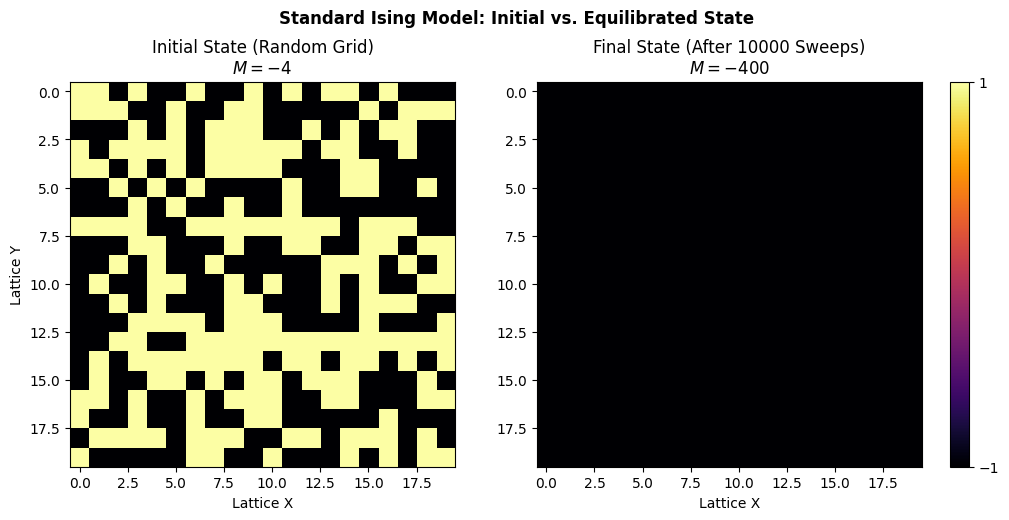

Initial Energy = 8.0
Initial Magnetization = -4
New Energy = -800.0
Initial Magnetization = -400


In [ ]:
grid = rng.choice([-1,1], size=(L,L))

initial_grid = grid.copy()
initial_M = np.sum(initial_grid)
initial_m = initial_M / N

final_grid = grid.copy()
for _ in range(sweeps):
    final_grid = sweep(final_grid)
final_M = np.sum(final_grid)
final_m = final_M / N

plt.figure(figsize=(12, 5))
plt.suptitle("Standard Ising Model: Initial vs. Equilibrated State", y=1.025, fontweight='bold')

plt.subplot(1, 2, 1)
im = plt.imshow(initial_grid, cmap="inferno", vmin=-1, vmax=1)
plt.title(f"Initial State (Random Grid)\n$M = {initial_M}$")
plt.xlabel("Lattice X")
plt.ylabel("Lattice Y")

plt.subplot(1, 2, 2)
plt.imshow(final_grid, cmap="inferno", vmin=-1, vmax=1)
plt.title(f"Final State (After {sweeps} Sweeps)\n$M = {final_M}$")
plt.xlabel("Lattice X")
plt.colorbar(im, ax=plt.gcf().get_axes(), fraction=0.05, pad=0.03, ticks=[-1, 1])

plt.show()

print(f"Initial Energy = {hamiltonian(grid)}")
print(f"Initial Magnetization = {initial_M}")

print(f"New Energy = {hamiltonian(final_grid)}")
print(f"Initial Magnetization = {final_M}")


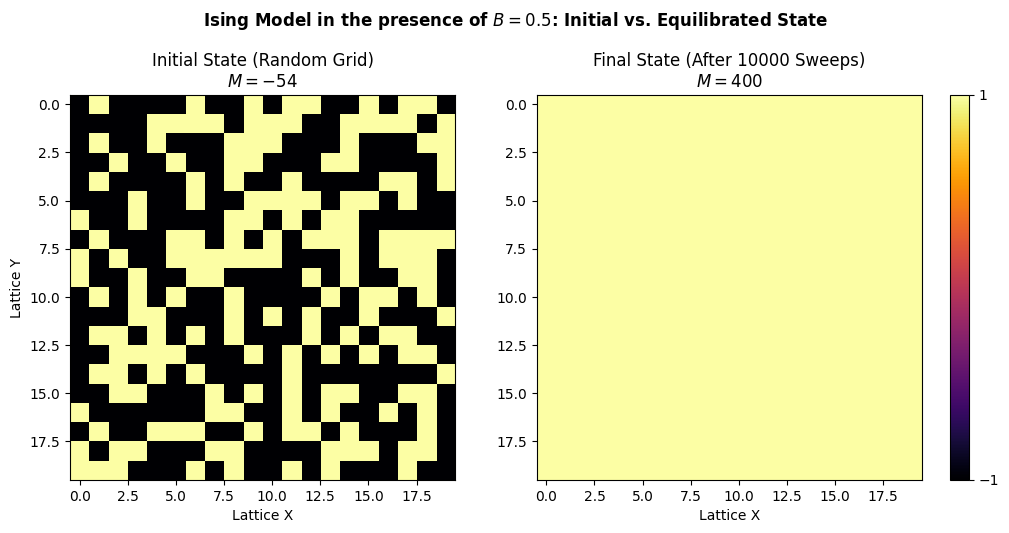

Initial Energy = 79.0
Initial Magnetization = -54
New Energy = -1000.0
Initial Magnetization = 400


In [ ]:
grid = rng.choice([-1,1], size=(L,L))

initial_grid = grid.copy()
initial_M = np.sum(initial_grid)
initial_m = initial_M / N

final_grid = grid.copy()
for _ in range(sweeps):
    final_grid = extB_sweep(final_grid)
final_M = np.sum(final_grid)
final_m = final_M / N

plt.figure(figsize=(12, 5))
plt.suptitle(f"Ising Model in the presence of $B={B}$: Initial vs. Equilibrated State", y=1.05, fontweight='bold')

plt.subplot(1, 2, 1)
im = plt.imshow(initial_grid, cmap="inferno", vmin=-1, vmax=1)
plt.title(f"Initial State (Random Grid)\n$M = {initial_M}$")
plt.xlabel("Lattice X")
plt.ylabel("Lattice Y")

plt.subplot(1, 2, 2)
plt.imshow(final_grid, cmap="inferno", vmin=-1, vmax=1)
plt.title(f"Final State (After {sweeps} Sweeps)\n$M = {final_M}$")
plt.xlabel("Lattice X")
plt.colorbar(im, ax=plt.gcf().get_axes(), fraction=0.05, pad=0.03, ticks=[-1, 1])

plt.show()

print(f"Initial Energy = {extB_hamiltonian(grid)}")
print(f"Initial Magnetization = {initial_M}")

print(f"New Energy = {extB_hamiltonian(final_grid)}")
print(f"Initial Magnetization = {final_M}")


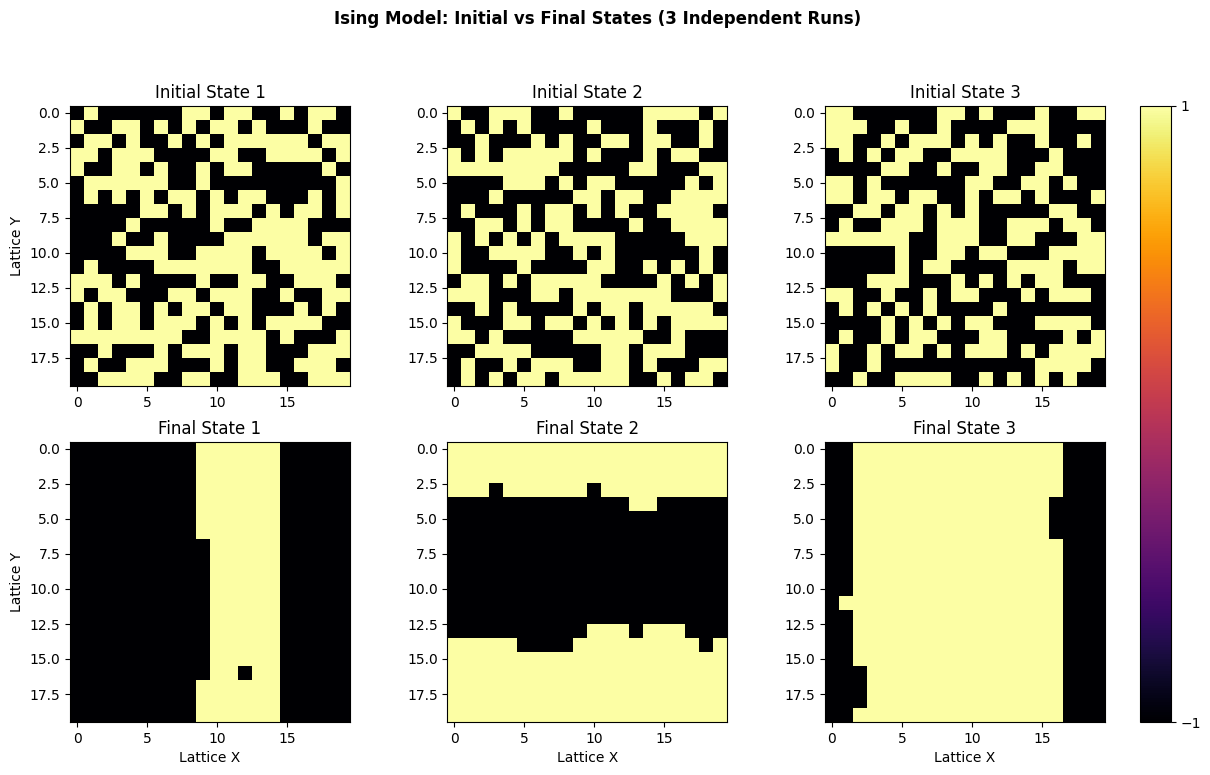

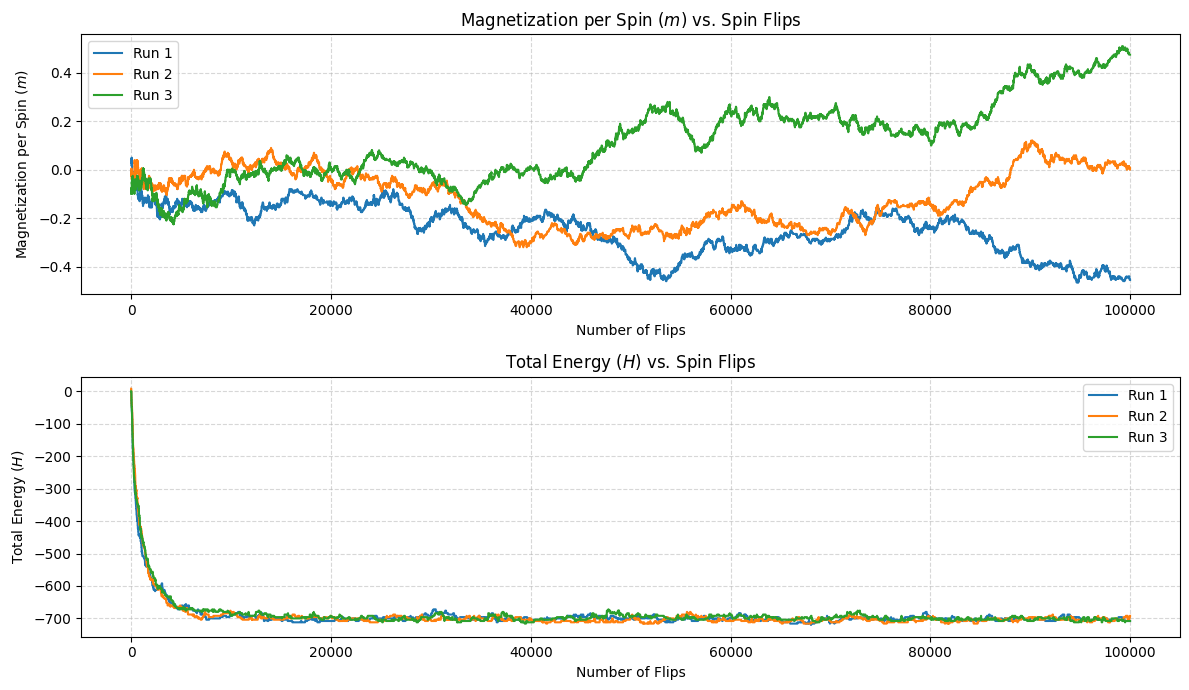

In [ ]:
N = 100000
T = 1
num_runs = 3

initial_grids = []
final_grids = []
all_m_vals = []
all_H_vals = []

def spontaneous_magnetization(grid, N, T=T, L=L, J=J):
    current_grid = grid.copy()
    m_vals = []
    H_vals = []

    for _ in range(N):
        i = rng.integers(0, L)
        j = rng.integers(0, L)
        flipped_grid = current_grid.copy()
        flipped_grid[i, j] = -flipped_grid[i, j]

        dH = hamiltonian(flipped_grid) - hamiltonian(current_grid)

        if flip_prob(dH):
            current_grid = flipped_grid

        m = np.sum(current_grid) / (L**2)
        H = hamiltonian(current_grid)

        m_vals.append(m)
        H_vals.append(H)

    return m_vals, H_vals, current_grid

for r in range(num_runs):
  grid_init = rng.choice([-1,1], size=(L,L))
  initial_grids.append(grid_init.copy())
  m_vals, H_vals, final_grid = spontaneous_magnetization(grid_init, N)
  final_grids.append(final_grid.copy())
  all_m_vals.append(m_vals)
  all_H_vals.append(H_vals)

plt.figure(figsize=(15,8))
plt.suptitle(f"Ising Model: Initial vs Final States ({num_runs} Independent Runs)", y=1.00, fontweight='bold')

for r in range(num_runs):
  plt.subplot(2, num_runs, r+1)
  im = plt.imshow(initial_grids[r], cmap="inferno", vmin=-1, vmax=1)
  plt.title(f"Initial State {r+1}")
  if r == 0:
    plt.ylabel("Lattice Y")

  plt.subplot(2, num_runs, r+4)
  im = plt.imshow(final_grids[r], cmap="inferno", vmin=-1, vmax=1)
  plt.title(f"Final State {r+1}")
  plt.xlabel("Lattice X")
  if r == 0:
    plt.ylabel("Lattice Y")

plt.colorbar(im, ax=plt.gcf().get_axes(), fraction=0.05, pad=0.03, ticks=[-1, 1])
plt.show()


plt.figure(figsize=(12,7))
plt.subplot(2, 1, 1)
for r in range(num_runs):
    plt.plot(range(N), all_m_vals[r], label=f"Run {r+1}")
plt.title("Magnetization per Spin ($m$) vs. Spin Flips")
plt.xlabel("Number of Flips")
plt.ylabel("Magnetization per Spin ($m$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.subplot(2, 1, 2)
for r in range(num_runs):
    plt.plot(range(N), all_H_vals[r], label=f"Run {r+1}")
plt.title("Total Energy ($H$) vs. Spin Flips")
plt.xlabel("Number of Flips")
plt.ylabel("Total Energy ($H$)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


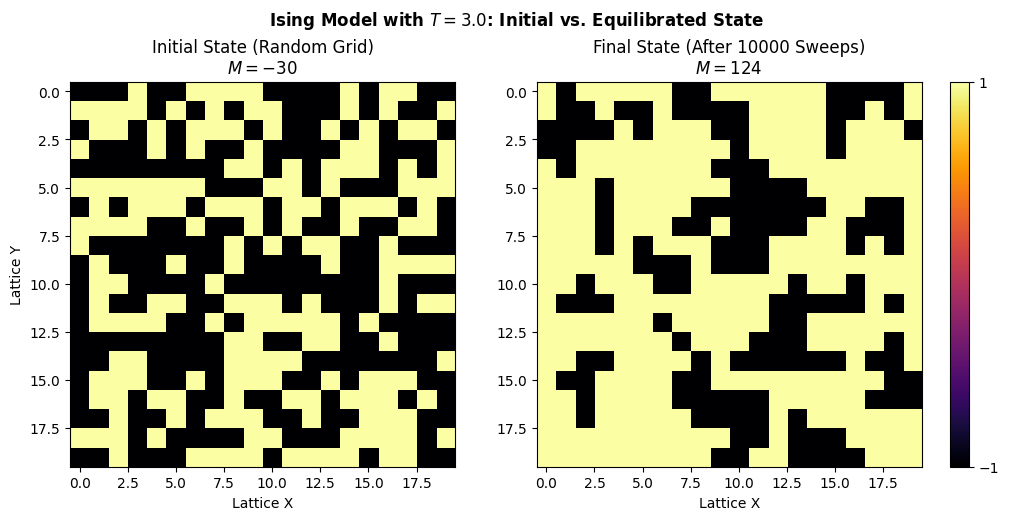

Initial Energy = -12.0
Initial Magnetization = -30
New Energy = -308.0
Initial Magnetization = 124


In [ ]:
T = 3.0

grid = rng.choice([-1,1], size=(L,L))

initial_grid = grid.copy()
initial_M = np.sum(initial_grid)
initial_m = initial_M / N

final_grid = grid.copy()
for _ in range(sweeps):
    final_grid = sweep(final_grid)
final_M = np.sum(final_grid)
final_m = final_M / N

plt.figure(figsize=(12, 5))
plt.suptitle(f"Ising Model with $T={T}$: Initial vs. Equilibrated State", y=1.025, fontweight='bold')

plt.subplot(1, 2, 1)
im = plt.imshow(initial_grid, cmap="inferno", vmin=-1, vmax=1)
plt.title(f"Initial State (Random Grid)\n$M = {initial_M}$")
plt.xlabel("Lattice X")
plt.ylabel("Lattice Y")

plt.subplot(1, 2, 2)
plt.imshow(final_grid, cmap="inferno", vmin=-1, vmax=1)
plt.title(f"Final State (After {sweeps} Sweeps)\n$M = {final_M}$")
plt.xlabel("Lattice X")
plt.colorbar(im, ax=plt.gcf().get_axes(), fraction=0.05, pad=0.03, ticks=[-1, 1])

plt.show()

print(f"Initial Energy = {hamiltonian(grid)}")
print(f"Initial Magnetization = {initial_M}")

print(f"New Energy = {hamiltonian(final_grid)}")
print(f"Initial Magnetization = {final_M}")


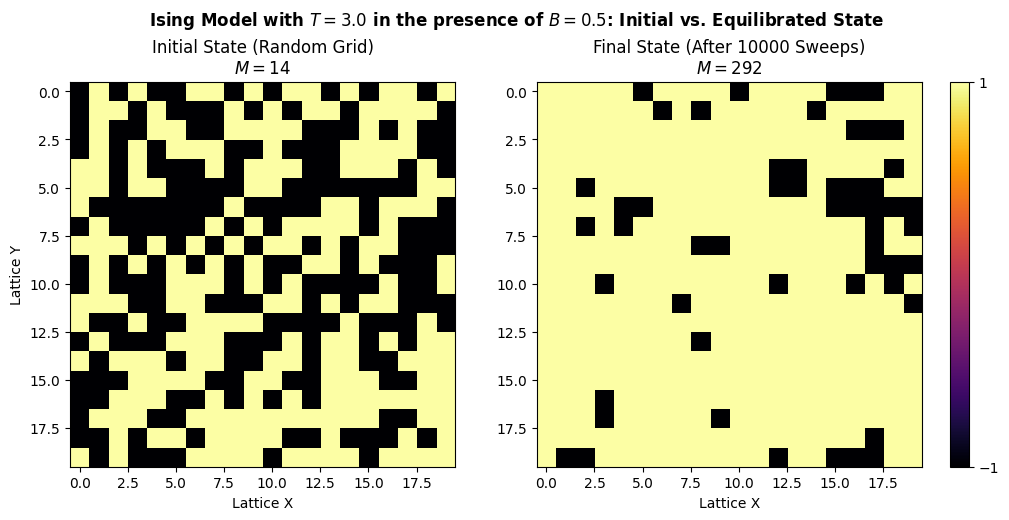

Initial Energy = -3.0
Initial Magnetization = 14
New Energy = -654.0
Initial Magnetization = 292


In [ ]:
T = 3.0

grid = rng.choice([-1,1], size=(L,L))

initial_grid = grid.copy()
initial_M = np.sum(initial_grid)
initial_m = initial_M / N

final_grid = grid.copy()
for _ in range(sweeps):
    final_grid = extB_sweep(final_grid)
final_M = np.sum(final_grid)
final_m = final_M / N

plt.figure(figsize=(12, 5))
plt.suptitle(f"Ising Model with $T={T}$ in the presence of $B={B}$: Initial vs. Equilibrated State", y=1.025, fontweight='bold')

plt.subplot(1, 2, 1)
im = plt.imshow(initial_grid, cmap="inferno", vmin=-1, vmax=1)
plt.title(f"Initial State (Random Grid)\n$M = {initial_M}$")
plt.xlabel("Lattice X")
plt.ylabel("Lattice Y")

plt.subplot(1, 2, 2)
plt.imshow(final_grid, cmap="inferno", vmin=-1, vmax=1)
plt.title(f"Final State (After {sweeps} Sweeps)\n$M = {final_M}$")
plt.xlabel("Lattice X")
plt.colorbar(im, ax=plt.gcf().get_axes(), fraction=0.05, pad=0.03, ticks=[-1, 1])

plt.show()

print(f"Initial Energy = {extB_hamiltonian(grid)}")
print(f"Initial Magnetization = {initial_M}")

print(f"New Energy = {extB_hamiltonian(final_grid)}")
print(f"Initial Magnetization = {final_M}")
